# Flight Regression Model (Linear Regression)

Modelo de regressao linear para estimar atraso de chegada (em minutos).

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from modules.smoothed_target_encoder import SmoothedTargetEncoder
from modules.cyclical_encoder import CyclicalEncoder
from modules.flight_preprocessor import FlightPreprocessor


In [52]:
df_flights = pd.read_csv("./data/flights.csv", low_memory=False)

# Set the columns to lower case
df_flights.columns = df_flights.columns.str.lower()
#df_flights = df_flights.fillna(0)
df_flights['is_delayed'] = (df_flights['arrival_delay'] > 15).astype(int)

In [53]:
df_airports = pd.read_csv("./data/airports.csv", low_memory=False)
df_airports.columns = df_airports.columns.str.lower()
df_airports = df_airports[['iata_code', 'state']]

In [54]:
processor = FlightPreprocessor()
df_flights = processor.preprocess(df_flights)

In [55]:
df_flights = df_flights.merge(
    df_airports,
    how='left',
    left_on='origin_airport',
    right_on='iata_code',
    suffixes=('', '_origin')
)

df_flights = df_flights.rename(columns={'state': 'state_origin'})
df_flights = df_flights.drop(columns=['iata_code'])

df_flights = df_flights.merge(
    df_airports,
    how='left',
    left_on='destination_airport',
    right_on='iata_code',
    suffixes=('', '_dest')
)

df_flights = df_flights.rename(columns={'state': 'state_dest'})
df_flights = df_flights.drop(columns=['iata_code'])


In [56]:
#variable that we know before the flight 
known_variables = [
    'airline', 'origin_airport', 'destination_airport',
    'state_origin', 'state_dest',
    'distance',
    'scheduled_departure', 'scheduled_arrival',
    'day_of_week', 'month', 'year',
    'is_delayed', 'arrival_delay', 'cancelled', 'diverted'
]
df_features = df_flights[known_variables].copy()

In [57]:
df_features.head()

,airline,origin_airport,destination_airport,state_origin,state_dest,distance,scheduled_departure,scheduled_arrival,day_of_week,month,year,is_delayed,arrival_delay,cancelled,diverted
0,AS,ANC,SEA,AK,WA,1448,2015-01-01 00:05:00,2015-01-01 04:30:00,3,1,2015,0,-22.0,0,0
1,AA,LAX,PBI,CA,FL,2330,2015-01-01 00:10:00,2015-01-01 07:50:00,3,1,2015,0,-9.0,0,0
2,US,SFO,CLT,CA,NC,2296,2015-01-01 00:20:00,2015-01-01 08:06:00,3,1,2015,0,5.0,0,0
3,AA,LAX,MIA,CA,FL,2342,2015-01-01 00:20:00,2015-01-01 08:05:00,3,1,2015,0,-9.0,0,0
4,AS,SEA,ANC,WA,AK,1448,2015-01-01 00:25:00,2015-01-01 03:20:00,3,1,2015,0,-21.0,0,0


In [58]:
# Target encoding for categorical features
enc_distance = SmoothedTargetEncoder('distance', 'is_delayed')
enc_origin = SmoothedTargetEncoder('origin_airport', 'is_delayed')
enc_destination = SmoothedTargetEncoder('destination_airport', 'is_delayed')
enc_airline = SmoothedTargetEncoder('airline', 'is_delayed')
enc_state_origin = SmoothedTargetEncoder('state_origin', 'is_delayed')
enc_state_dest = SmoothedTargetEncoder('state_dest', 'is_delayed')

if 'origin_airport' in df_features.columns:
    df_features['origin_airport_encoded'] = enc_origin.fit_transform(df_features)
if 'destination_airport' in df_features.columns:
    df_features['destination_airport_encoded'] = enc_destination.fit_transform(df_features)
if 'airline' in df_features.columns:
    df_features['airline_encoded'] = enc_airline.fit_transform(df_features)
if 'state_origin' in df_features.columns:
    df_features['state_origin'] = enc_state_origin.fit_transform(df_features)
if 'state_dest' in df_features.columns:
    df_features['state_dest'] = enc_state_dest.fit_transform(df_features)


In [59]:
# Time features with cyclical encoding
if 'scheduled_departure' in df_features.columns:
    df_features['scheduled_departure'] = pd.to_datetime(df_features['scheduled_departure'])
if 'scheduled_arrival' in df_features.columns:
    df_features['scheduled_arrival'] = pd.to_datetime(df_features['scheduled_arrival'])

# Departure
if 'scheduled_departure' in df_features.columns:
    df_features['dep_hour'] = (
        df_features['scheduled_departure'].dt.hour +
        df_features['scheduled_departure'].dt.minute / 60
    )
    df_features['dep_dayofyear'] = df_features['scheduled_departure'].dt.dayofyear

# Arrival
if 'scheduled_arrival' in df_features.columns:
    df_features['arr_hour'] = (
        df_features['scheduled_arrival'].dt.hour +
        df_features['scheduled_arrival'].dt.minute / 60
    )
    df_features['arr_dayofyear'] = df_features['scheduled_arrival'].dt.dayofyear

if 'dep_dayofyear' in df_features.columns:
    dep_enc_day = CyclicalEncoder('dep_dayofyear', period=365)
    df_features = dep_enc_day.fit_transform(df_features)
if 'dep_hour' in df_features.columns:
    dep_enc_hour = CyclicalEncoder('dep_hour', period=24)
    df_features = dep_enc_hour.fit_transform(df_features)
if 'arr_dayofyear' in df_features.columns:
    arr_enc_day = CyclicalEncoder('arr_dayofyear', period=365)
    df_features = arr_enc_day.fit_transform(df_features)
if 'arr_hour' in df_features.columns:
    arr_enc_hour = CyclicalEncoder('arr_hour', period=24)
    df_features = arr_enc_hour.fit_transform(df_features)


In [60]:
df_processed.columns

Index(['distance', 'origin_airport_encoded', 'is_delayed', 'arrival_delay',
       'cancelled', 'diverted'],
      dtype='object')

In [61]:
final_features = [
    'distance',
    'origin_airport_encoded', 'destination_airport_encoded', 'airline_encoded',
    'dep_dayofyear_sin', 'dep_dayofyear_cos',
    'dep_hour_sin', 'dep_hour_cos',
    'arr_dayofyear_sin', 'arr_dayofyear_cos',
    'arr_hour_sin', 'arr_hour_cos',
    'is_delayed', 'arrival_delay', 'cancelled', 'diverted'
]

final_features = [f for f in final_features if f in df_features.columns]

df_processed = df_features[final_features].copy()
df_processed.head()


,distance,origin_airport_encoded,destination_airport_encoded,airline_encoded,dep_dayofyear_sin,dep_dayofyear_cos,dep_hour_sin,dep_hour_cos,arr_dayofyear_sin,arr_dayofyear_cos,arr_hour_sin,arr_hour_cos,is_delayed,arrival_delay,cancelled,diverted
0,1448,0.117408,0.155344,0.122971,0.017213,0.999852,0.021815,0.999762,0.017213,0.999852,0.923880,0.382683,0,-22.0,0,0
1,2330,0.198610,0.216695,0.172742,0.017213,0.999852,0.043619,0.999048,0.017213,0.999852,0.887011,-0.461749,0,-9.0,0,0
2,2296,0.192121,0.148261,0.175863,0.017213,0.999852,0.087156,0.996195,0.017213,0.999852,0.852640,-0.522499,0,5.0,0,0
3,2342,0.197842,0.196137,0.172308,0.017213,0.999852,0.087156,0.996195,0.017213,0.999852,0.854912,-0.518773,0,-9.0,0,0
4,1448,0.159041,0.166936,0.123137,0.017213,0.999852,0.108867,0.994056,0.017213,0.999852,0.766044,0.642788,0,-21.0,0,0


In [62]:
# 1) Remova cancelados/desviados (recomendado)
df_model = df_processed[(df_processed['cancelled'] == 0) & (df_processed['diverted'] == 0)].copy()

# 2) Garanta que o target existe e não é NaN
df_model = df_model.dropna(subset=['arrival_delay'])

# (opcional) se você decidiu modelar só atrasos (sem adiantamentos):
df_model['arrival_delay'] = df_model['arrival_delay'].clip(lower=0)

# 3) Separe X e y
X = df_model.drop(columns=[
    'arrival_delay',
    'is_delayed',
    'cancelled',
    'diverted'
])

y = df_model['arrival_delay'].clip(lower=0)



In [ ]:
X = df_model.drop(columns=['arrival_delay'])
y = df_model['arrival_delay']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

y_pred = lin_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)

### Model Evaluation Results (Test Set) ###")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.4f}")

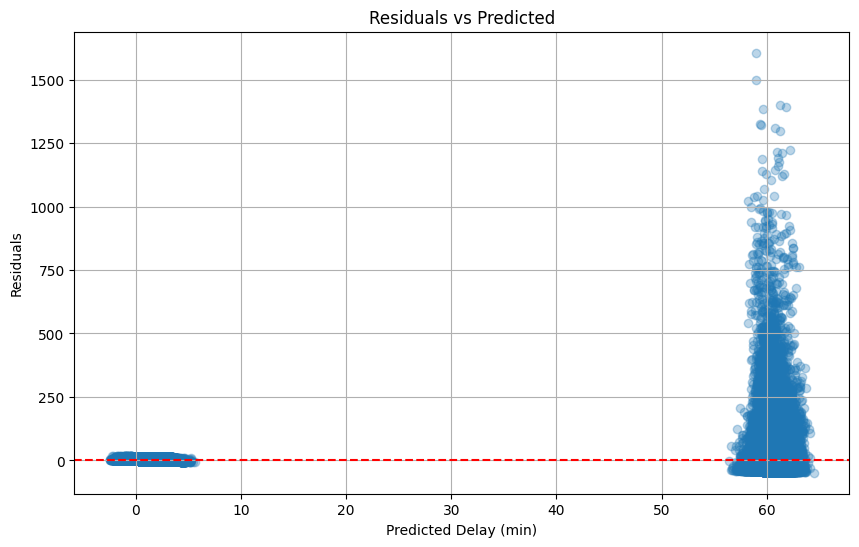

In [65]:
# Residual analysis
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Delay (min)')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.grid(True)
plt.show()


In [67]:
X = df_model.drop(columns=['arrival_delay'])
y = df_model['arrival_delay']
y_log = np.log1p(y)


X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

y_pred = lin_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)

### Model Evaluation Results (Test Set) ###")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.4f}")

MAE: 0.64
RMSE: 0.81
R2: 0.7210


c:\Users\User\OneDrive\Documents\Git Workspace\fiap-machine-learning-tech-challenge-3\.venv\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


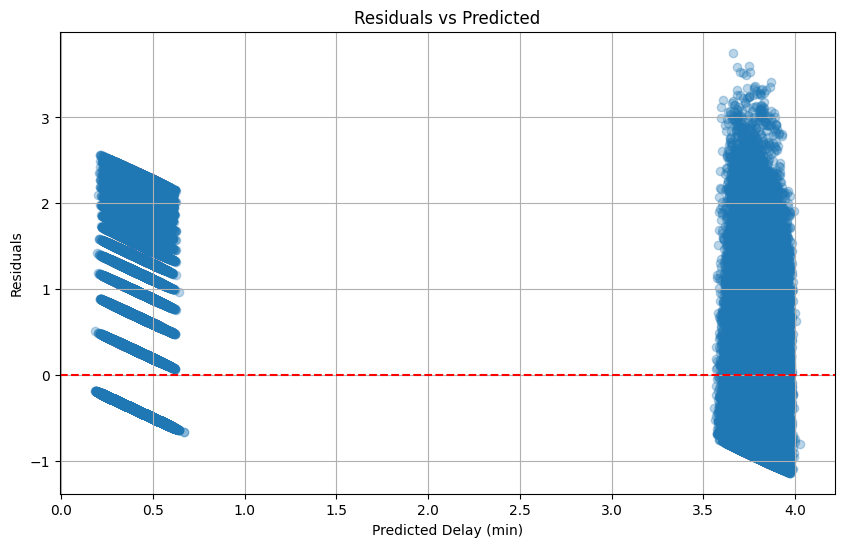

In [68]:
# Residual analysis
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Delay (min)')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.grid(True)
plt.show()


In [66]:
np.unique(y_test, return_counts=True)

(array([0.000e+00, 1.000e+00, 2.000e+00, 3.000e+00, 4.000e+00, 5.000e+00,
        6.000e+00, 7.000e+00, 8.000e+00, 9.000e+00, 1.000e+01, 1.100e+01,
        1.200e+01, 1.300e+01, 1.400e+01, 1.500e+01, 1.600e+01, 1.700e+01,
        1.800e+01, 1.900e+01, 2.000e+01, 2.100e+01, 2.200e+01, 2.300e+01,
        2.400e+01, 2.500e+01, 2.600e+01, 2.700e+01, 2.800e+01, 2.900e+01,
        3.000e+01, 3.100e+01, 3.200e+01, 3.300e+01, 3.400e+01, 3.500e+01,
        3.600e+01, 3.700e+01, 3.800e+01, 3.900e+01, 4.000e+01, 4.100e+01,
        4.200e+01, 4.300e+01, 4.400e+01, 4.500e+01, 4.600e+01, 4.700e+01,
        4.800e+01, 4.900e+01, 5.000e+01, 5.100e+01, 5.200e+01, 5.300e+01,
        5.400e+01, 5.500e+01, 5.600e+01, 5.700e+01, 5.800e+01, 5.900e+01,
        6.000e+01, 6.100e+01, 6.200e+01, 6.300e+01, 6.400e+01, 6.500e+01,
        6.600e+01, 6.700e+01, 6.800e+01, 6.900e+01, 7.000e+01, 7.100e+01,
        7.200e+01, 7.300e+01, 7.400e+01, 7.500e+01, 7.600e+01, 7.700e+01,
        7.800e+01, 7.900e+01, 8.000e+0